In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [29]:
# Data loading ../data/filtered_df.csv and  ../data/oil_data.csv and ../results/sig_pairs.csv
df = pd.read_csv('../data/filtered_df.csv', index_col=0)
df_oil = pd.read_csv('../data/oil_data.csv')
df_sig = pd.read_csv('../results/sig_pairs.csv')

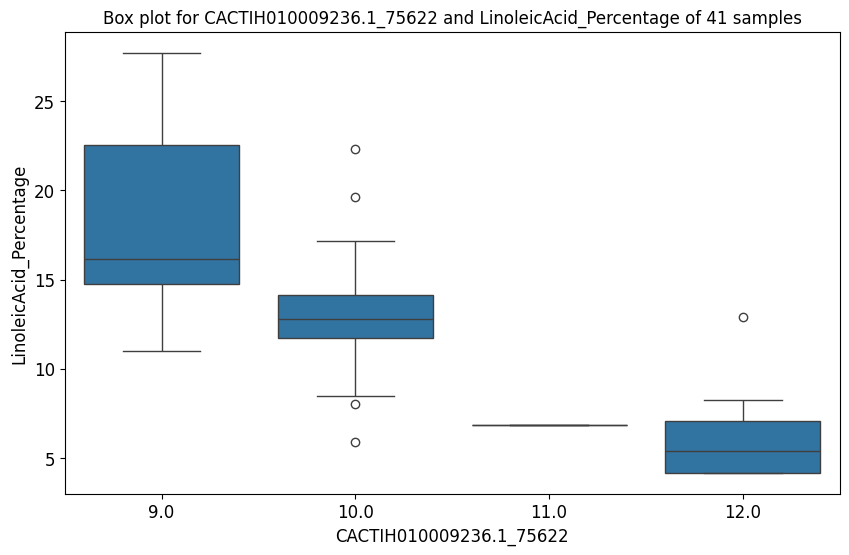

In [61]:
# for a selected pair in df_sig, get the corresponding data from df and df_oil and plot them
index = 0
row = df_sig.iloc[index]    
oil_ = row['oil_feature']
str_ = row['str_id']   
df_pair = df.loc[str_,] 
df_pair = df_pair.reset_index().rename(columns={'index': 'sample_id', str_: str_})
df_pair = df_pair.merge(df_oil[["Sample_ID", oil_]], left_on='sample_id', right_on='Sample_ID')

plt.figure(figsize=(10, 6), dpi=100)    
sns.boxplot(data=df_pair, x= str_, y= oil_)
plt.title(f'Box plot for {str_} and {oil_} of {row["n_samples"]} samples')
# change font size of x and y labels and axis ticklabels
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlabel(f'{str_}', fontsize=12)    
plt.ylabel(f'{oil_}', fontsize=12)
plt.show()